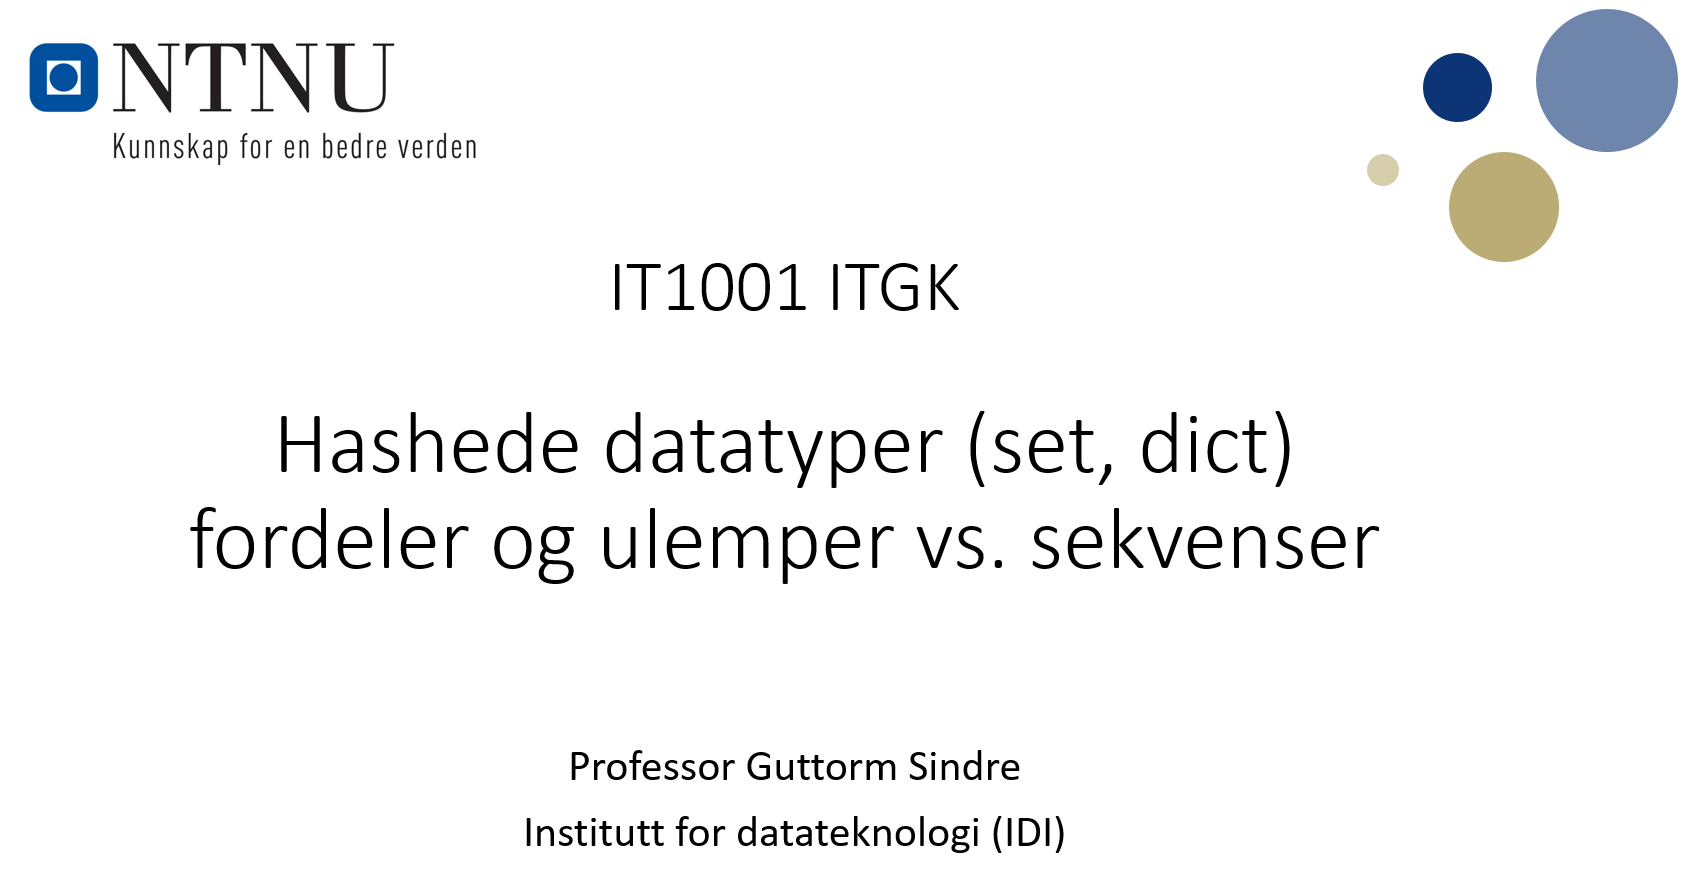

# Sammensatte datatyper
- hvor hver variabel kan inneholde mange verdier

Hittil har vi sett på følgende typer:
- tupler
- lister
- numpy array

Disse har mye felles
- alle er _sekvenser_, dvs. data ligger i en viss rekkefølge
- enkeltelement kan aksesseres med __[indeks]__ som må være heltall
- kan bruke _slicing_ for utdrag av dataene


## Tupler, lister, array, forts.
Også noen forskjeller:
- muterbarhet
    - tuple er immuterbar, kan ikke gjøre "change in place"
    - array er muterbar, men kun med endring av verdier, ikke lengde
        - men formen kan endres så lenge total lengde er uforandret, se eksempel under
    - liste er muterbar, kan både endre, fjerne og legge til element
- homogen vs. heterogen
    - array er homogen, alle element må være samme type
        - f.eks. alle int, eller alle float
    - tuple og list er heterogene, kan blande data av ulike typer
    
Effektive beregninger
- array muliggjør effektive beregninger
    - kan utføre samme aritmetiske operasjon på alle elementer på en gang
    - følger bl.a. av homogeniteten, alle element har samme type
- mens lister / tupler i så fall må bruke løkke gjennom elementene

In [ ]:
# En numpy-array har en underliggende buffer som holder på dataene. 
# VI kan ha flere "views" av den samme bufferen, som betyr at vi kan ha flere arrays som refererer til den samme dataen.
# For eksempel, når vi bruker reshape() på en array, så lager vi et nytt "view" som refererer til den samme bufferen som den opprinnelige arrayen.

import numpy as np

A = np.arange(1,16)
print(A)

B = A.reshape(3,5)

print(B)  # B har en annen shape enn A, men refererer til den samme bufferen som A. Derfor vil endringer i A også påvirke B, og vice versa.
B[1,1] = 99 # Endrer verdi i B, som har felles data med A. Derfor vil endringen også vises i A.
print(A)

# Nå: Enda to sammensatte datatyper
- mengder (set)
- ordbøker (dictionary)
## ... men hvorfor?

Mengder og ordbøker er __ikke__ sekvenser
- gir ikke mening å snakke om første eller siste element, dvs. vanlig indeksering som i lister
- men de er fortsatt `itererbare`,
    - dvs. at vi kan gå gjennom element for element i en for-løkke
    - vi kan *konvertere* dem til lister, tupler, **i en ikke-spesifisert rekkefølge**

De er derimot __hashede__ datatyper. Se annet sted for en forenklet forklaring.

Dette har både fordeler og ulemper, men er tilpasset *andre behov* enn sekvenser.

### Eksempel: lister, hva er de raske og trege til?
- Raskt: finne element med gitt indeks (hva står i __my_list[579]__ ?)
- Tregt: finne element med en gitt verdi ("Ruby" in my_list?)
- Raskt: sette inn element bakerst (my_list.append("Ruby"))
- Tregt: sette inn element andre sted i lista (f.eks. midt, fremst)
    - fordi
Illustrerer dette ved å lage ei skikkelig lang liste
- og så bruke en funksjon timeit som kan ta tiden på utførelse av kode

In [ ]:
# Lager ei skikkelig lang liste, 10001 element
my_list = list(range(0,30001,3))  # [0,3,6,...,30000]
print(len(my_list))

In [ ]:
import timeit #har en funksjon for tidtaking

my_list = list(range(0,30001,3))  # [0,3,6,...,30000]
liste_oppslag_indeks = timeit.timeit("my_list[5000]", number=10000, globals=globals())
liste_oppslag_verdi = timeit.timeit("15000 in my_list", number=10000, globals=globals())
liste_sett_inn_bak = timeit.timeit("my_list.append(1)", number=10000, globals=globals())
liste_sett_inn_fremst = timeit.timeit("my_list.insert(0,1)", number=10000, globals=globals())
print(f'{"Oppslag på indeks":20} {liste_oppslag_indeks:.6f}')
print(f'{"Oppslag på verdi":20} {liste_oppslag_verdi:.6f}')
print(f'{"Innsetting bak":20} {liste_sett_inn_bak:.6f}')
print(f'{"Innsetting fremst":20} {liste_sett_inn_fremst:.6f}')

## Her er en av styrkene til mengder

In [ ]:
# Lager ei mengde (set) med akkurat samme data som lista
my_set = set(range(0,30001,3))   # {0,3,6,...,30000}
mengde_oppslag_verdi = timeit.timeit("15000 in my_set", number=10000, globals=globals())
mengde_innsetting = timeit.timeit("my_set.add(15000)", number=10000, globals=globals())
print(f'{"Mengde, oppslag på verdi":40} {mengde_oppslag_verdi:.6f}      (liste hadde ): {liste_oppslag_verdi:.6f}')
print(f'{"Mengde, innsetting vilkårlig posisjon":40} {mengde_innsetting:.6f}      (liste fremst): {liste_sett_inn_fremst:.6f}')

## Fordeler med mengder
Mye raskere oppslag på verdier
- cirka like raskt som oppslag på indeks i ei liste

Mye raskere innsetting og fjerning av element hvor som helst i mengden
- om trent like raskt som det lister klarer bakerst

Så hvorfor ikke heller bruke mengder hele tida? 
- jo, fordi det fins også begrensninger:
    - kan ikke inneholde dupliserte verdier (men det finnes multiset også)
    - holder ikke rede på rekkefølge på elementene
    - tilbyr ikke effektive aritmetiske operasjoner (i motsetning til array)
    - bruker vesentlig mer minneplass

Dette er det generelle poenget med hashede datastrukturer
- oppnår raske oppslag på verdi og rask fjerning og innsetting av verdier
- men til en kostnad: større forbruk av minneplass

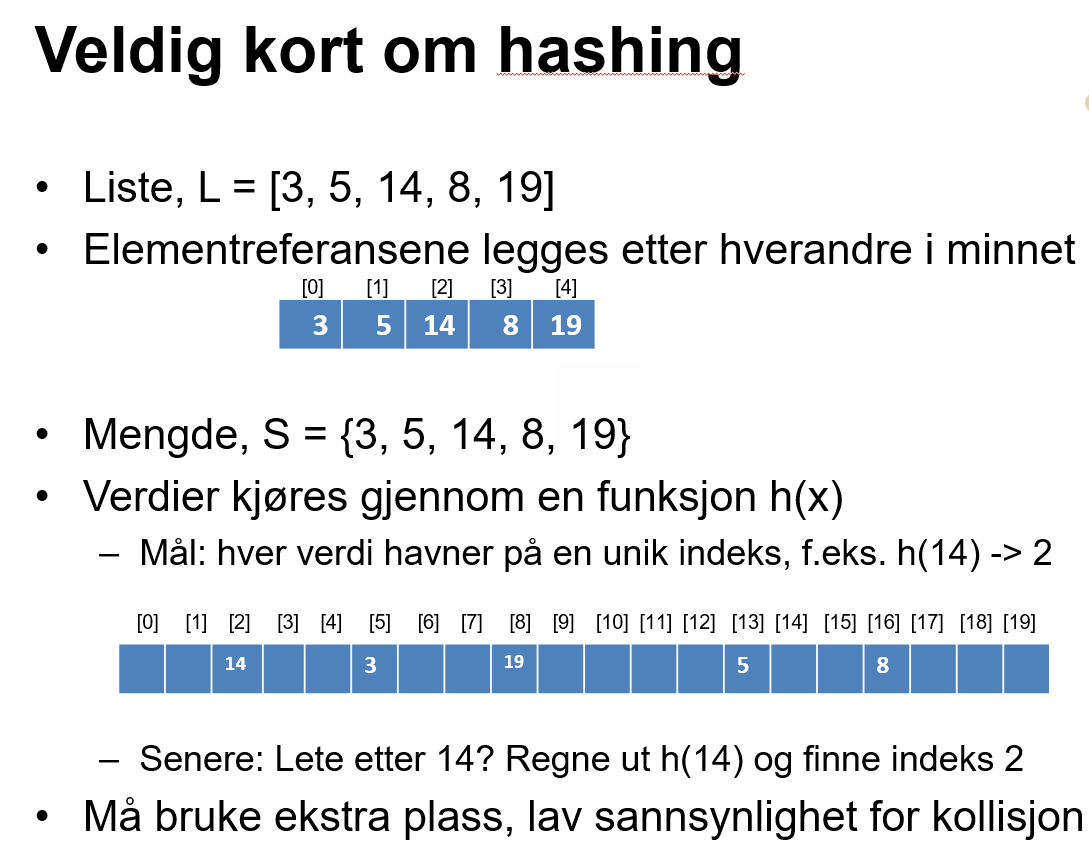

## Datatypenes bruk av minneplass

In [ ]:
#Sammenligner bruk av minneplass
import numpy as np
import sys #har en funksjon for plassforbruk

# Lager array, liste, tuppel, mengde med elementene 0, 3, 6, ... 30000
my_arr = np.arange(0,30001,3)   # [[0 3 6 ... 30000]
my_list = list(range(0,30001,3))  # [0,3,6,...,30000]
my_tuple = tuple(range(0,30001,3)) # (0,3,6,...,30000)
my_set = set(range(0,30001,3))   # {0,3,6,...,30000}

print("Plassforbruk, variable")
print(f'Array {sys.getsizeof(my_arr)}')
print(f'Liste {sys.getsizeof(my_list)}')
print(f'Tuppel {sys.getsizeof(my_tuple)}')
print(f'Mengde {sys.getsizeof(my_set)}')

## Tidsbruk for oppslag på verdi

In [ ]:
# Sammenligner tidsbruk for oppslag på verdi
import numpy as np
import timeit #har en funksjon for tidtaking

print("Tidsforbruk, oppslag på verdi")
print(f'Array {timeit.timeit("15000 in my_arr", number=10000, globals=globals())}')
print(f'Liste {timeit.timeit("15000 in my_list", number=10000, globals=globals())}')
print(f'Tuppel {timeit.timeit("15000 in my_tuple", number=10000, globals=globals())}')
print(f'Mengde {timeit.timeit("15000 in my_set", number=10000, globals=globals())}')

## Tidsbruk, innsetting og fjerning

In [ ]:
print("Tidsforbruk, sette inn nye verdier")
print(f'Liste innsetting bakerst {timeit.timeit("my_list.append(1)", number=10000, globals=globals())}')
print(f'Liste innsetting midten {timeit.timeit("my_list.insert(5000, 1)", number=10000, globals=globals())}')
print(f'Liste innsetting fremst {timeit.timeit("my_list.insert(0, 1)", number=10000, globals=globals())}')
print(f'Mengde innsetting alle {timeit.timeit("my_set.add(1)", number=10000, globals=globals())}')
print()
print("Tidsforbruk, fjerne element")
print(f'Liste fjerne bakerst {timeit.timeit("del my_list[-1]", number=10000, globals=globals())}')
print(f'Liste fjerne midten {timeit.timeit("del my_list[5000]", number=10000, globals=globals())}')
print(f'Liste fjerne fremst {timeit.timeit("del my_list[0]", number=10000, globals=globals())}')
print(f'Mengde fjerne generelt {timeit.timeit("my_set.discard(0)", number=10000, globals=globals())}')

## Oppsummering: Fordeler, ulemper med ulike datatyper
Tuppel:
- ivaretar rekkefølge på data
- tillater blanding av ulike typer data
- immuterbar
    - fordel hvis dette er data som IKKE skal endres: hindrer utilsiktet mutering
    - ulempe hvis du trenger å endre data i tuppelet: må lage nytt tuppelobjekt
- raske oppslag på indeks, men trege oppslag på verdi
- tuppel kan være element i mengde og nøkkel i dictionary

Liste:
- som tuppel (rekkefølge, blanding av datatyper), bare at den er muterbar
- stor fleksibilitet: tillater både endring, tillegg og fjerning av element
- som tuppel: raske oppslag på indeks, treg på verdi
- raskt å legge til / fjerne noe bakerst, mye tregere midt i eller fremst i lista

Array:
- mindre fleksibel enn liste:
    - alle element må ha samme datatype
    - tillater kun endring av verdier, ikke fjerne / legge til element
- til gjengjeld: mye mer effektive regneoperajoner
- raskere oppslag på verdi enn liste og tuppel (men tregere enn mengde)

Mengde (set):
- svært raske oppslag på verdi, samt fjerne / legge til
    - holder ikke rede på rekkefølge på element
    - kan ikke inneholde dupliserte element
    - er en endimensjonal datastruktur (inneholder kun de hashede nøklene)
        - alternativ til 1D liste (hvis rekkefølge ikke er viktig)
    
Ordbok (dictionary):
- som mengde: raske oppslag på nøkkelverdier, samt fjerne / legge til nøkler
- fordel vs. mengde:
    - kan inneholde mer data tilknyttet hver nøkkel
    - alternativ til 2D liste

## Når er mengder og dictionaries mest hensiktsmessige?
Når vi trenger
- raske oppslag på verdi
- rask innsetting og fjerning av element, og ikke bare bakerst
- når rekkefølge på data ikke er viktig
    - dette gjelder aller mest for mengder

Dictionaries kan ha rekkefølge på de underliggende dataene som tilhører hver nøkkel
- kan f.eks. ha lister inni seg

In [ ]:
def f(x,y,z):
    s[:] = z
    y[:] = s
    y[0] = 3
    x = [7,7,7]
    
s = [1,2,3]
u = [4,5,6]
w = [7,7,7]
f(s, u, w)
print(s)
print(u)
print(w)


In [ ]:
def f(x, y, z):
    s = z
    s[:] = y
    y = x
    x[0] = 3

s = [1,2,3]
u = [4,5,6]
w = [7,7,7]
f(s, u, w)
print(s)
print(u)
print(w)

In [ ]:
def f(x, y, z):
    s[:] = z
    y = s
    z[0] = 3
    z = [7, 7, 7]
    
s = [1,2,3]
u = [4,5,6]
w = [7,7,7]
f(s, u, w)
print(s)
print(u)
print(w)

In [ ]:
def f(x, y, z):
    s[0] = 3
    y = z
    y[0] = 3
    x = z

s = [1,2,3]
u = [4,5,6]
w = [7,7,7]
f(s, u, w)
print(s)
print(u)
print(w)

In [ ]:
def f(x, y, z):
    y[0] = 3
    z[0] = x[0]
    z = [9, 8, 7]
    x = z
    
s = [1,2,3]
u = [4,5,6]
w = [7,7,7]
f(s, u, w)
print(s)
print(u)
print(w)